In [15]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/vinothkannaece/mobiles-and-laptop-sales-data/mobile_sales_data.csv


In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

In [28]:
penguins=sns.load_dataset('penguins')
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [29]:
penguins["species"].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

In [30]:
penguins["island"].value_counts()

island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

<Axes: xlabel='flipper_length_mm', ylabel='body_mass_g'>

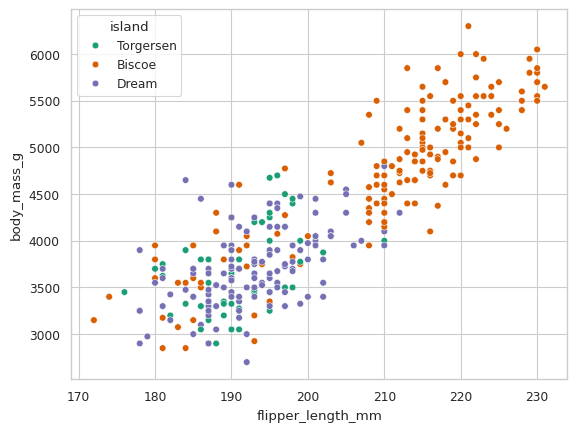

In [41]:
sns.set_style('whitegrid')
sns.set_context("paper")
# set_context can be used to override default
sns.scatterplot(data=penguins,x="flipper_length_mm",y='body_mass_g',hue='island', palette='Dark2')

<Axes: xlabel='species', ylabel='body_mass_g'>

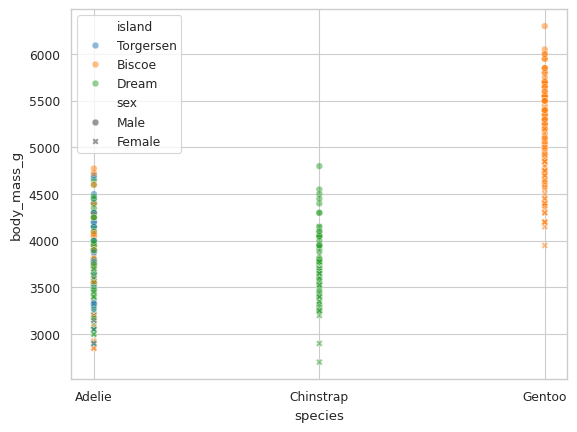

In [43]:
sns.scatterplot(data=penguins, x='species',y='body_mass_g',hue='island', style='sex', alpha=0.5)
# higher opacity using alpha

<Axes: xlabel='species', ylabel='body_mass_g'>

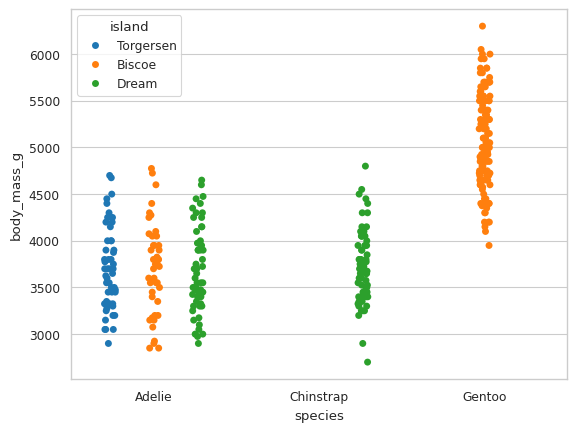

In [48]:
sns.stripplot(data=penguins, x='species',y='body_mass_g',hue='island', dodge=True)
# dodge=true helps split data in 'Adelie'

<Axes: xlabel='species', ylabel='body_mass_g'>

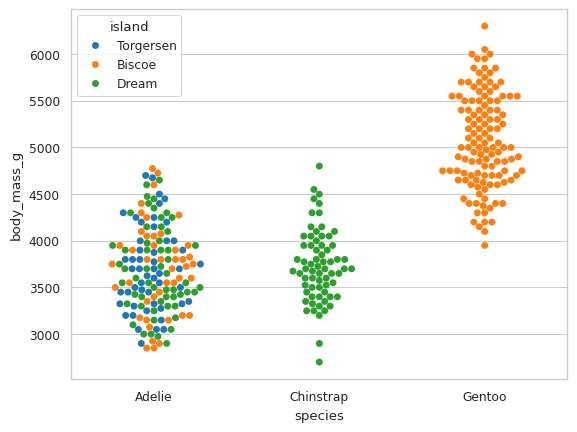

In [49]:
# gives a swamp shape to the random data points
sns.swarmplot(data=penguins,x='species',y='body_mass_g',hue='island')

<Axes: xlabel='body_mass_g', ylabel='Count'>

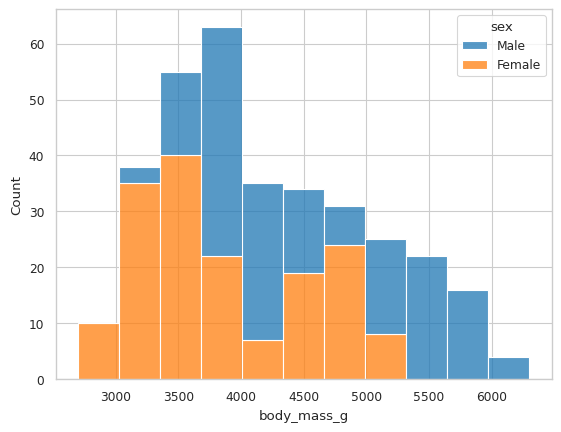

In [52]:
sns.histplot(data=penguins, x='body_mass_g', hue='sex', multiple='stack')

<Axes: xlabel='body_mass_g', ylabel='flipper_length_mm'>

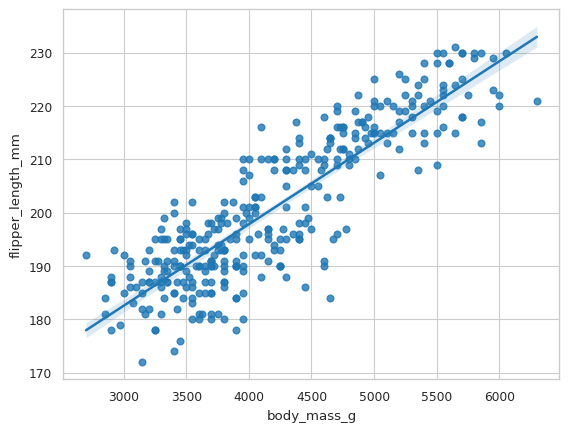

In [53]:
# regression plot, linear line
sns.regplot(data=penguins, x='body_mass_g',y='flipper_length_mm')

<Axes: xlabel='body_mass_g', ylabel='flipper_length_mm'>

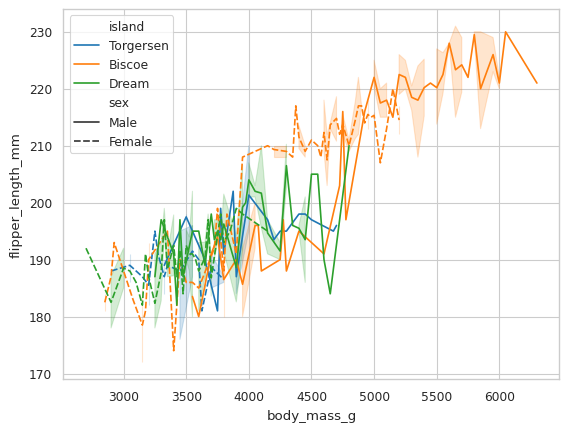

In [57]:
# Line plot 

sns.lineplot(data=penguins, x='body_mass_g',y='flipper_length_mm', hue='island', style='sex')

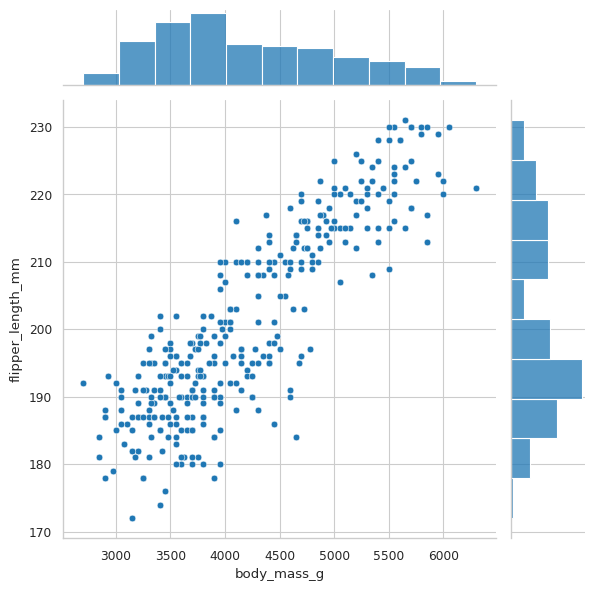

In [59]:
sns.jointplot(data=penguins,x='body_mass_g',y='flipper_length_mm')

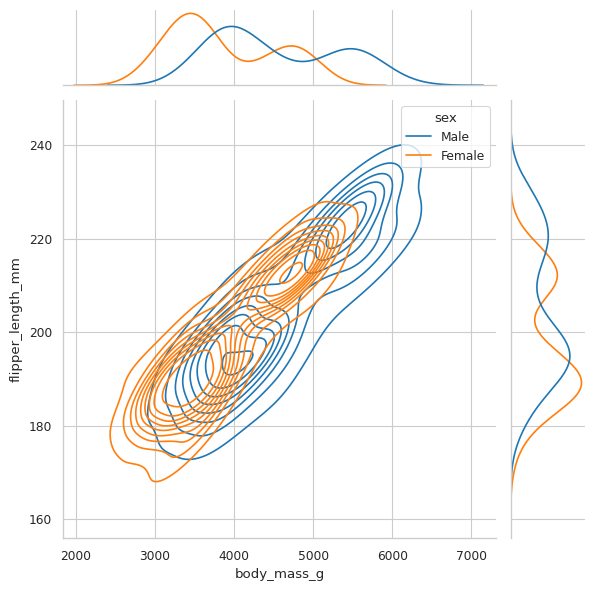

In [62]:
sns.jointplot(data=penguins,x='body_mass_g',y='flipper_length_mm', hue='sex',kind='kde')

<Axes: xlabel='species', ylabel='body_mass_g'>

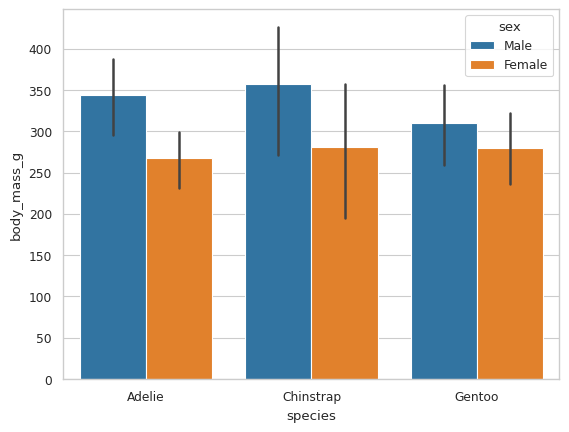

In [68]:
sns.barplot(data=penguins,x='species',y='body_mass_g', hue='sex', estimator=np.std)
# estimator: the scale to find sums, medians, etc

<Axes: xlabel='species', ylabel='count'>

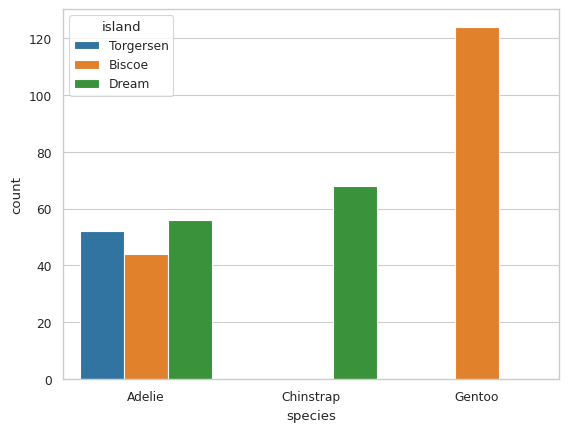

In [70]:
sns.countplot(data=penguins,x='species',hue='island')

<Axes: xlabel='species', ylabel='body_mass_g'>

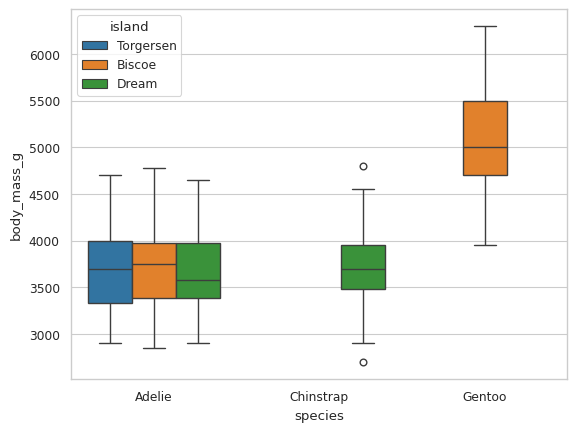

In [71]:
# identifying outliers, uses 25%,75%,95%
sns.boxplot(data=penguins,x='species',y='body_mass_g', hue='island')

<Axes: xlabel='species', ylabel='body_mass_g'>

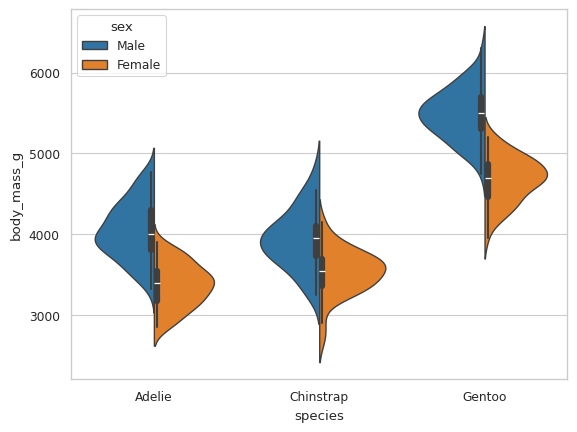

In [74]:
# Violin plot 
sns.violinplot(data=penguins,x='species',y='body_mass_g', hue='sex', split=True)

<Axes: xlabel='species', ylabel='body_mass_g'>

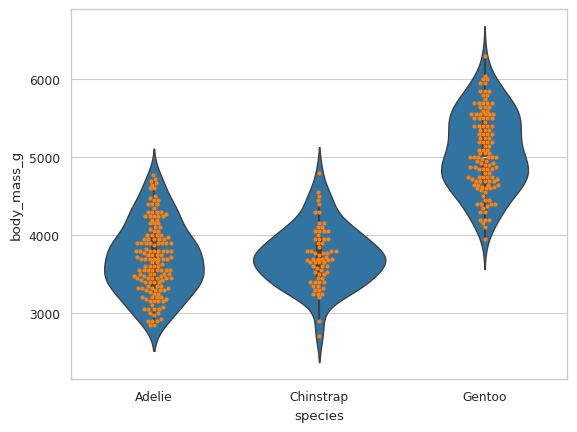

In [75]:
sns.violinplot(data=penguins,x='species',y='body_mass_g')
sns.swarmplot(data=penguins,x='species',y='body_mass_g',size=3)

<Axes: xlabel='body_mass_g', ylabel='Density'>

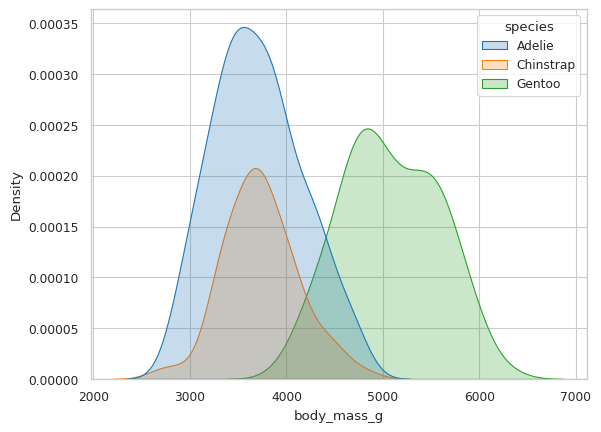

In [78]:
sns.kdeplot(data=penguins,x='body_mass_g',hue='species', fill=True)

In [85]:
cols=['bill_length_mm', 'bill_depth_mm',	'flipper_length_mm','body_mass_g']
penguins[cols].corr()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000000,-0.235053,0.656181,0.595110
bill_depth_mm,-0.235053,1.000000,-0.583851,-0.471916
flipper_length_mm,0.656181,-0.583851,1.000000,0.871202
body_mass_g,0.595110,-0.471916,0.871202,1.000000


<Axes: >

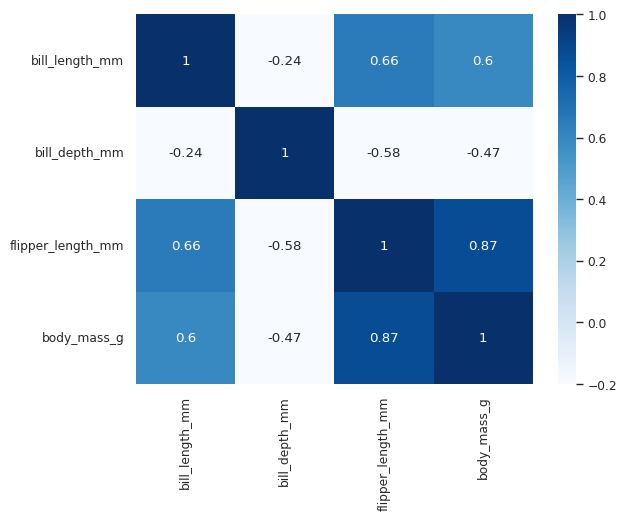

In [92]:
# Heatmap
cols=['bill_length_mm', 'bill_depth_mm',	'flipper_length_mm','body_mass_g']
sns.heatmap(data=penguins[cols].corr(), annot=True, vmin=-0.2, cmap='Blues')

<Axes: xlabel='body_mass_g'>

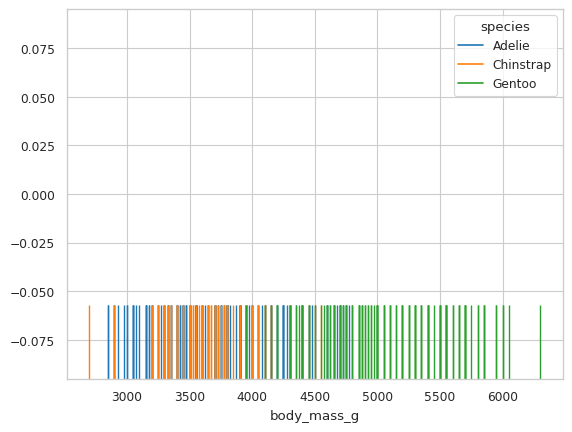

In [94]:
sns.rugplot(data=penguins,x='body_mass_g',hue='species', height=0.2)

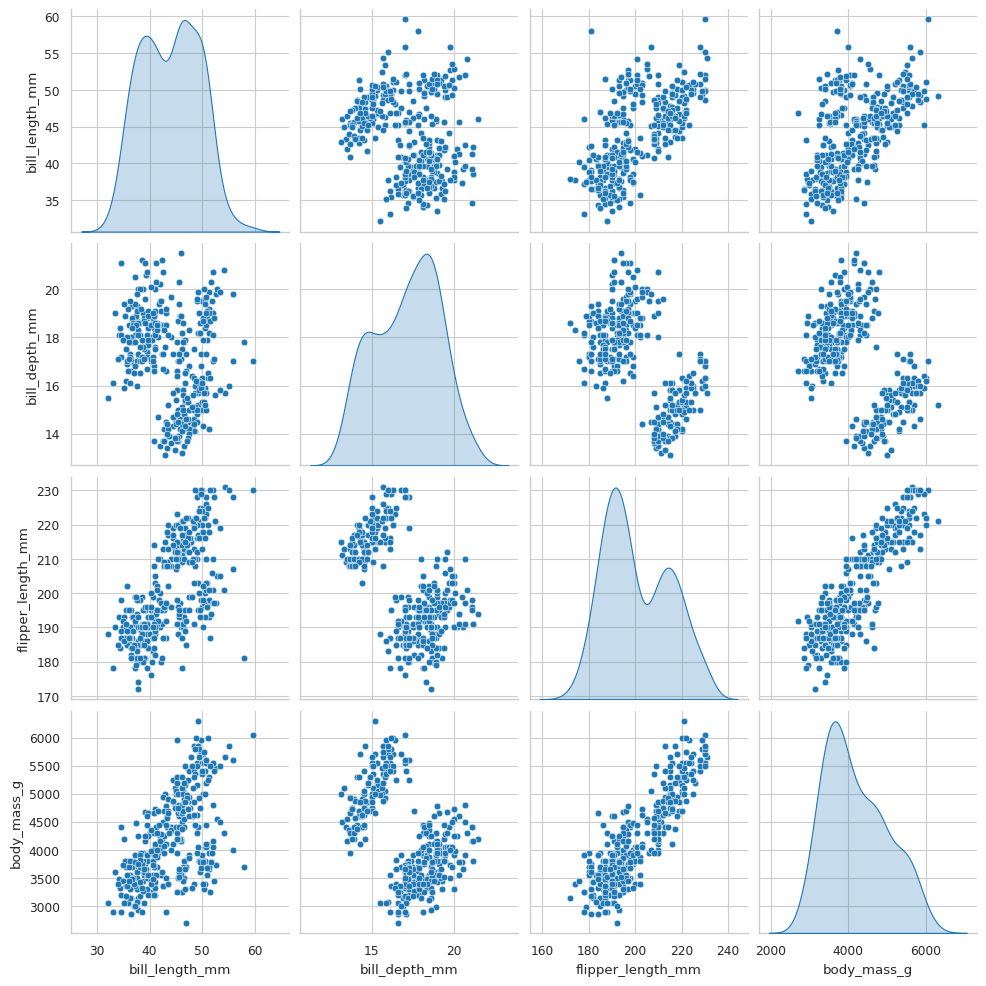

In [97]:
sns.pairplot(data=penguins[cols], diag_kind='kde')

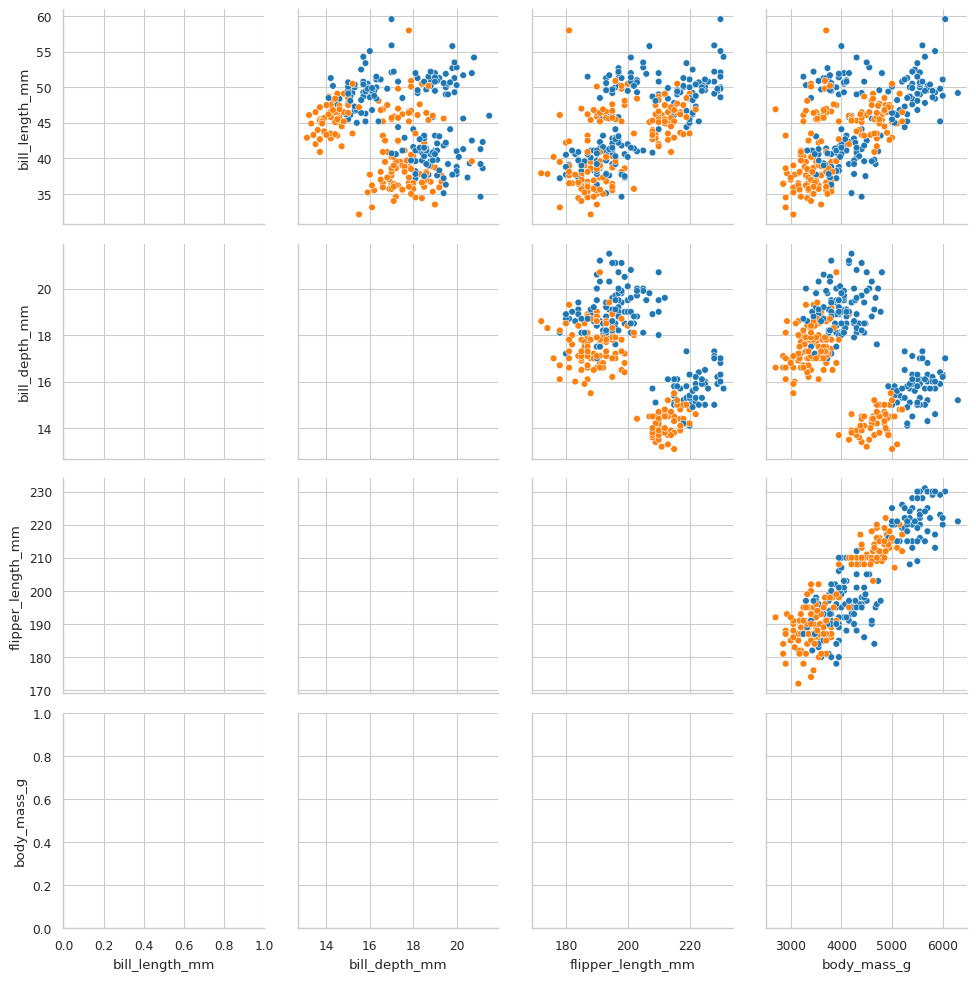

In [101]:
# pair grid for plotting pairware relationships in a dataset
graph = sns.PairGrid(data=penguins,hue='sex')
graph.map_upper(sns.scatterplot)